In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_squared_error, r2_score

import matplotlib.pyplot as plt

# **LOAD DATASET**

In [3]:
df = pd.read_csv("car data.csv")

print(df.head())
print(df.info())

  Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Seller_Type Transmission  Owner  
0      Dealer       Manual      0  
1      Dealer       Manual      0  
2      Dealer       Manual      0  
3      Dealer       Manual      0  
4      Dealer       Manual      0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non

# ** DATA CLEANING**

In [4]:
# Renommer la cible
df.rename(columns={'Selling_Price': 'price'}, inplace=True)

# Supprimer colonne inutile
df.drop('Car_Name', axis=1, inplace=True)

# Supprimer doublons
df = df.drop_duplicates()

# Gérer valeurs manquantes
for col in df.columns:
    if df[col].dtype == 'object':
        df[col].fillna(df[col].mode()[0], inplace=True)
    else:
        df[col].fillna(df[col].median(), inplace=True)


/tmp/ipykernel_9605/2251916344.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)
/tmp/ipykernel_9605/2251916344.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try 

# **. FEATURE ENGINEERING**

In [5]:
# Création nouvelles variables

df['age'] = 2026 - df['Year']
df['price_per_km'] = df['price'] / (df['Kms_Driven'] + 1)
df['price_to_value'] = df['price'] / (df['Present_Price'] + 1)

# Encodage catégoriel

df = pd.get_dummies(df, columns=['Fuel_Type', 'Seller_Type', 'Transmission'], drop_first=True)

print("\nColumns after encoding:", df.columns)


Columns after encoding: Index(['Year', 'price', 'Present_Price', 'Kms_Driven', 'Owner', 'age',
       'price_per_km', 'price_to_value', 'Fuel_Type_Diesel',
       'Fuel_Type_Petrol', 'Seller_Type_Individual', 'Transmission_Manual'],
      dtype='object')


# **SPLIT DATA**

In [6]:
X = df.drop('price', axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# **. NORMALIZATION**

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# **MODELS**

In [8]:
models = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "ElasticNet": ElasticNet(),
    "Tree": DecisionTreeRegressor(max_depth=5),
    "SVR": SVR()
}

# **EVALUATION FUNCTION**

In [9]:
def evaluate(model, X_train, X_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return {
        "MSE": mean_squared_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred)
    }


# **TRAIN + RESULTS**

In [10]:
results = {}

for name, model in models.items():
    if name in ["Linear", "Tree"]:
        results[name] = evaluate(model, X_train, X_test)
    else:
        results[name] = evaluate(model, X_train_scaled, X_test_scaled)

print("\n=== MODEL RESULTS ===")
for model, res in results.items():
    print(model, res)

# Tableau propre
results_df = pd.DataFrame(results).T
print("\n=== RESULTS TABLE ===")
print(results_df)



=== MODEL RESULTS ===
Linear {'MSE': 3.9179770775286977, 'R2': 0.8479828807177332}
Ridge {'MSE': 3.8899203088605945, 'R2': 0.8490714805397577}
Lasso {'MSE': 7.279026488016346, 'R2': 0.7175744992909658}
ElasticNet {'MSE': 5.052111921037812, 'R2': 0.8039785620664744}
Tree {'MSE': 51.06061730378251, 'R2': -0.981146851474511}
SVR {'MSE': 15.316461646804155, 'R2': 0.4057228179055271}

=== RESULTS TABLE ===
                  MSE        R2
Linear       3.917977  0.847983
Ridge        3.889920  0.849071
Lasso        7.279026  0.717574
ElasticNet   5.052112  0.803979
Tree        51.060617 -0.981147
SVR         15.316462  0.405723


# **CROSS VALIDATION**

In [11]:
print("\n=== CROSS VALIDATION (R2) ===")
for name, model in models.items():
    if name in ["Linear", "Tree"]:
        scores = cross_val_score(model, X, y, cv=5, scoring='r2')
    else:
        X_scaled = scaler.fit_transform(X)
        scores = cross_val_score(model, X_scaled, y, cv=5, scoring='r2')

    print(name, "Mean R2:", scores.mean())



=== CROSS VALIDATION (R2) ===
Linear Mean R2: -2.944249916656016
Ridge Mean R2: -2.9884591102431743
Lasso Mean R2: -4.262891385413674
ElasticNet Mean R2: -17.637040775149647
Tree Mean R2: -2.377296549487961
SVR Mean R2: -3.9235437746016366


# **GRID SEARCH (EXAMPLE)**

In [12]:
# =============================================
# 🔧 HYPERPARAMETER TUNING : RIDGE
# =============================================

# Définir les valeurs de alpha à tester
# alpha = paramètre de régularisation (plus grand = plus de pénalité)
param_grid_ridge = {'alpha': [0.01, 0.1, 1, 10]}

# GridSearchCV va tester toutes les combinaisons de paramètres
# cv=5 → validation croisée en 5 parties
grid_ridge = GridSearchCV(Ridge(), param_grid_ridge, cv=5)

# Entraîner le modèle avec toutes les combinaisons
grid_ridge.fit(X_train_scaled, y_train)

# Afficher le meilleur paramètre trouvé
print("\nBest Ridge Params:", grid_ridge.best_params_)


# =============================================
# 🔧 HYPERPARAMETER TUNING : SVR
# =============================================

# Définir les paramètres à tester
param_grid_svr = {
    'C': [0.1, 1, 10],         # contrôle la pénalité des erreurs
    'gamma': ['scale', 'auto'] # contrôle l'influence des points
}

# GridSearch pour SVR
grid_svr = GridSearchCV(SVR(), param_grid_svr, cv=5)

# Entraînement avec toutes les combinaisons
grid_svr.fit(X_train_scaled, y_train)

# Affichage des meilleurs paramètres
print("Best SVR Params:", grid_svr.best_params_)


Best Ridge Params: {'alpha': 10}
Best SVR Params: {'C': 10, 'gamma': 'auto'}


# **FEATURE IMPORTANCE (TREE)**

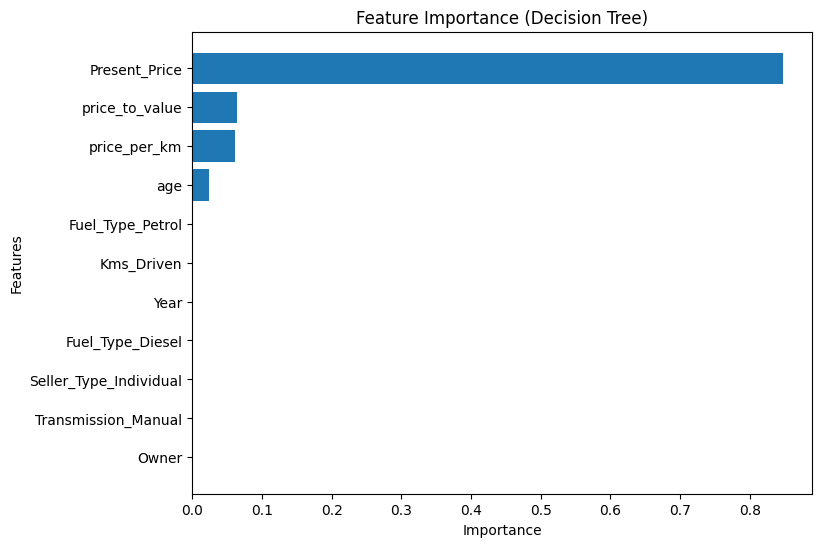

In [13]:

#  FEATURE IMPORTANCE (DECISION TREE)

# Créer et entraîner le modèle Decision Tree
tree = DecisionTreeRegressor()
tree.fit(X_train, y_train)

# Récupérer l'importance des variables
# Chaque valeur indique l'importance d'une feature dans la prédiction
importances = tree.feature_importances_

# Récupérer les noms des colonnes (features)
feature_names = X_train.columns

# Trier les variables par importance
indices = np.argsort(importances)


#  VISUALISATION
plt.figure(figsize=(8,6))

# Graphique horizontal avec noms des variables
plt.barh(range(len(indices)), importances[indices])

# Afficher les noms des features
plt.yticks(range(len(indices)), feature_names[indices])

plt.title("Feature Importance (Decision Tree)")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()


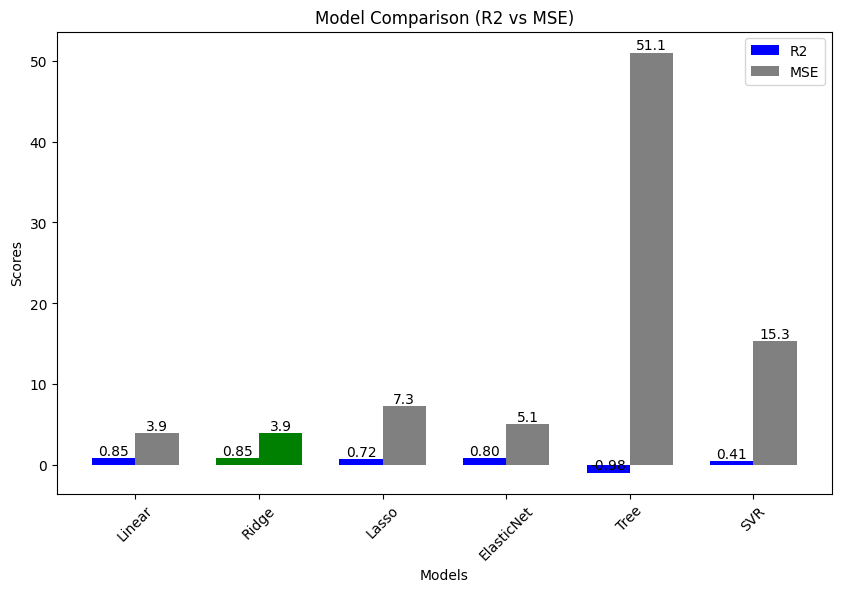

Best model based on R2: Ridge


In [14]:
# =============================================
#  COMBINED GRAPH : R2 + MSE
# =============================================

import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# Récupération des données
# -----------------------------

# noms des modèles (index du DataFrame)
models = results_df.index

# scores R2 (mesure de performance)
r2_scores = results_df['R2']

# scores MSE (mesure d'erreur)
mse_scores = results_df['MSE']

# -----------------------------
# Identifier le meilleur modèle
# -----------------------------

# le meilleur modèle est celui avec le R2 le plus élevé
best_model = r2_scores.idxmax()

# -----------------------------
# Préparation du graphique
# -----------------------------

# positions sur l’axe X
x = np.arange(len(models))

# largeur des barres
width = 0.35

# création de la figure
plt.figure(figsize=(10,6))

# -----------------------------
# Définition des couleurs
# -----------------------------

# couleur pour R2 (vert si meilleur modèle, sinon bleu)
colors_r2 = ['green' if model == best_model else 'blue' for model in models]

# couleur pour MSE (vert si meilleur modèle, sinon gris)
colors_mse = ['green' if model == best_model else 'grey' for model in models]

# -----------------------------
# Création des barres
# -----------------------------

# barres R2 (à gauche)
bars1 = plt.bar(x - width/2, r2_scores, width, label='R2', color=colors_r2)

# barres MSE (à droite)
bars2 = plt.bar(x + width/2, mse_scores, width, label='MSE', color=colors_mse)

# -----------------------------
# Affichage des valeurs sur les barres
# -----------------------------

# valeurs R2
for bar in bars1:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height,
             f'{height:.2f}', ha='center', va='bottom')

# valeurs MSE
for bar in bars2:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height,
             f'{height:.1f}', ha='center', va='bottom')

# -----------------------------
# Labels et mise en forme
# -----------------------------

# noms des modèles sur l’axe X
plt.xticks(x, models, rotation=45)

# titre du graphique
plt.title("Model Comparison (R2 vs MSE)")

# labels des axes
plt.xlabel("Models")
plt.ylabel("Scores")

# légende
plt.legend()

# -----------------------------
# Affichage final
# -----------------------------

plt.show()

# -----------------------------
# Affichage du meilleur modèle
# -----------------------------

print("Best model based on R2:", best_model)
